# **Question 1**

# **230051L Arachchi.A.D.I.D** 

Github link - https://github.com/isithadinujaya/Vision-Assignment-2

In [3]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter


In [4]:
im = cv.imread("/kaggle/input/datasets/isithadinujaya/images-a-2/a2images/a2images/the_berry_farms_sunflower_field.jpeg",cv.IMREAD_REDUCED_COLOR_4)

gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0

In [5]:
sigma_min = 1.5
sigma_max = 25.0
number_of_scales = 30
threshold_relative = 0.12

sigmas = np.geomspace(sigma_min, sigma_max, number_of_scales)

scale_ratio = sigmas[1] / sigmas[0]
evaluation_sigmas = np.concatenate(([sigmas[0] / scale_ratio],sigmas,[sigmas[-1] * scale_ratio]))

In [6]:
responses = np.stack([
    np.abs(sigma**2 * gaussian_laplace(gray, sigma=sigma, mode="reflect")) for sigma in evaluation_sigmas], axis=0)


In [7]:
local_maximum = maximum_filter( responses, size=(3, 3, 3),mode="constant",cval=-np.inf)

threshold = threshold_relative * responses[1:-1].max()

extrema = ((responses == local_maximum) & (responses > threshold))

extrema[0] = False
extrema[-1] = False

scale_indices, ys, xs = np.where(extrema)

candidates = []

for scale_index, y, x in zip(scale_indices, ys, xs):
    sigma = evaluation_sigmas[scale_index]
    radius = np.sqrt(2.0) * sigma

    if (x - radius < 0 or y - radius < 0 or x + radius >= gray.shape[1] or y + radius >= gray.shape[0]):
        continue

    candidates.append((
        float(x),
        float(y),
        float(sigma),
        float(radius),
        float(responses[scale_index, y, x])
    ))


In [8]:
candidates.sort(key=lambda blob: blob[4], reverse=True)
blobs = []

for candidate in candidates:
    x, y, sigma, radius, response = candidate

    duplicate = any(
        np.hypot(x - kept[0], y - kept[1])
        < 0.5 * (radius + kept[3])
        for kept in blobs
    )

    if not duplicate:
        blobs.append(candidate)

Detection sigma range: 1.50–25.00 pixels
Number of detection scales: 30
Detected circles: 993

Largest circles, measured in the reduced image:
Rank        x        y     sigma    radius
   1     96.0    144.0    25.000    35.355
   2    224.0     83.0    22.689    32.086
   3     28.0     63.0    16.959    23.984
   4     52.0    103.0    16.959    23.984
   5    292.0    293.0    15.391    21.767
   6    198.0    292.0    13.968    19.754
   7    337.0    165.0    12.677    17.928
   8    269.0    149.0    12.677    17.928
   9    204.0    152.0    12.677    17.928
  10    221.0     24.0    12.677    17.928


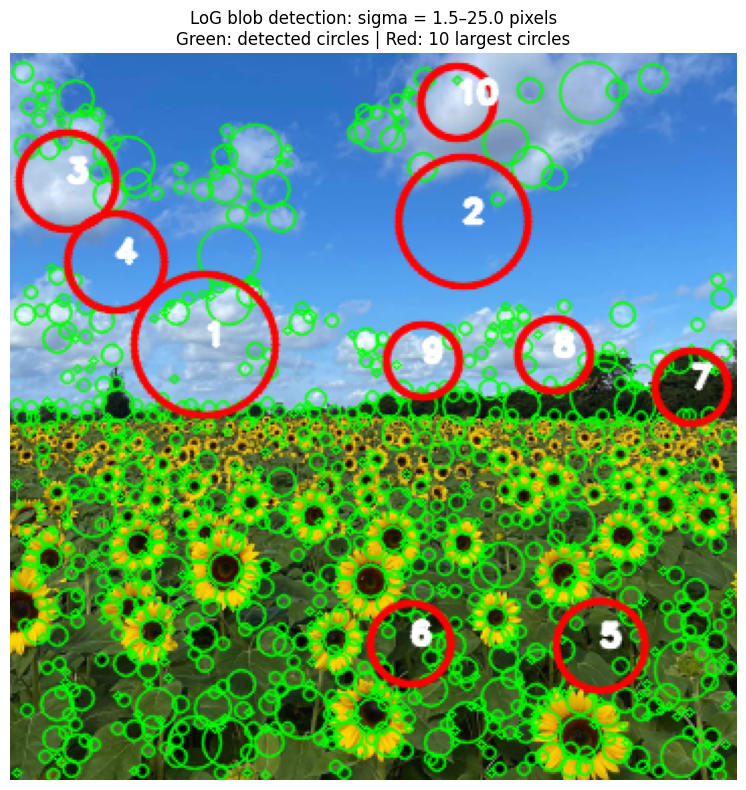

In [9]:
largest = sorted(blobs, key=lambda blob: blob[3], reverse=True)[:10]

print(f"Detection sigma range: {sigma_min:.2f}–{sigma_max:.2f} pixels")
print(f"Number of detection scales: {number_of_scales}")
print(f"Detected circles: {len(blobs)}")
print("\nLargest circles, measured in the reduced image:")
print(f"{'Rank':>4} {'x':>8} {'y':>8} {'sigma':>9} {'radius':>9}")

for rank, (x, y, sigma, radius, response) in enumerate(largest, 1):
    print(
        f"{rank:4d} {x:8.1f} {y:8.1f} "
        f"{sigma:9.3f} {radius:9.3f}"
    )

output = im.copy()

for x, y, sigma, radius, response in blobs:
    cv.circle(output,(round(x), round(y)),round(radius),(0, 255, 0),1,cv.LINE_AA)

for rank, (x, y, sigma, radius, response) in enumerate(largest, 1):
    center = (round(x), round(y))

    cv.circle(output, center, round(radius),(0, 0, 255), 2, cv.LINE_AA)

    cv.putText(output, str(rank), center,cv.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255),2,cv.LINE_AA)

cv.imwrite("sunflower_log_circles.jpg", output)

plt.figure(figsize=(16, 8))
plt.imshow(cv.cvtColor(output, cv.COLOR_BGR2RGB))
plt.title(
    f"LoG blob detection: sigma = {sigma_min}–{sigma_max} pixels\n"
    "Green: detected circles | Red: 10 largest circles"
)
plt.axis("off")
plt.tight_layout()
plt.show()


# **Question 2**

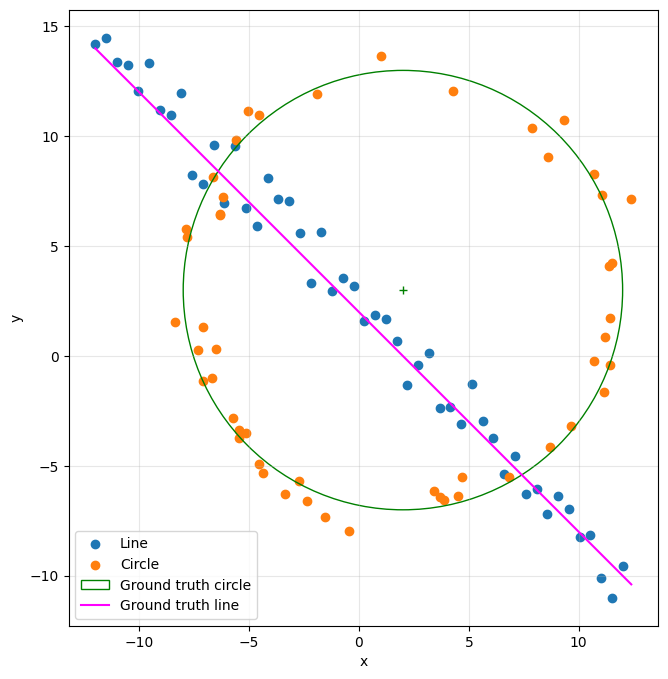

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.random.seed(0)

N = 100
half_n = N // 2

r = 10
x0_gt, y0_gt = 2, 3
s = r / 16

t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)

x = x0_gt + (r + n) * np.cos(t)
y = y0_gt + (r + n) * np.sin(t)

X_circ = np.column_stack((x, y))

s = 1.0
m, b_gt = -1, 2

x = np.linspace(-12, 12, half_n)
y = m * x + b_gt + s * np.random.randn(half_n)

X_line = np.column_stack((x, y))
X = np.vstack((X_circ, X_line))

fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(X_line[:, 0], X_line[:, 1], label="Line")
ax.scatter(X_circ[:, 0], X_circ[:, 1], label="Circle")

ax.add_patch(plt.Circle((x0_gt, y0_gt), r,color="green", fill=False,label="Ground truth circle"))

ax.plot(x0_gt, y0_gt, "+", color="green")

x_plot = np.array([X[:, 0].min(), X[:, 0].max()])
ax.plot(x_plot, m * x_plot + b_gt, color="magenta",
        label="Ground truth line")

ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [4]:
rng = np.random.default_rng(42)

threshold = 1.5
min_inliers = 40
iterations = 1000

best_mask = None
best_normal = None
best_d = None
best_count = 0
best_error = np.inf

for _ in range(iterations):
    indices = rng.choice(len(X), 2, replace=False)
    p1, p2 = X[indices]

    direction = p2 - p1
    length = np.linalg.norm(direction)

    if length < 1e-12:
        continue

    normal = np.array([-direction[1], direction[0]]) / length
    d_candidate = normal @ p1

    distances = np.abs(X @ normal - d_candidate)
    mask = distances <= threshold

    count = np.count_nonzero(mask)

    if count < min_inliers:
        continue

    error = np.mean(distances[mask] ** 2)

    if count > best_count or (count == best_count and error < best_error):
        best_count = count
        best_error = error
        best_mask = mask.copy()
        best_normal = normal.copy()
        best_d = d_candidate


In [5]:
def line_objective(parameters, points):
    theta, d = parameters
    normal = np.array([np.cos(theta), np.sin(theta)])
    residuals = points @ normal - d
    return np.sum(residuals ** 2)


theta_initial = np.arctan2(best_normal[1], best_normal[0])

result = minimize(line_objective,x0=np.array([theta_initial, best_d]),args=(X[best_mask],),method="Powell")

if not result.success:
    raise RuntimeError(result.message)

theta, d = result.x
a, b = np.cos(theta), np.sin(theta)

if d < 0:
    a, b, d = -a, -b, -d

normal = np.array([a, b])
distances = np.abs(X @ normal - d)
inlier_mask = distances <= threshold

if inlier_mask.sum() < min_inliers:
    raise RuntimeError("Refined line has insufficient consensus.")

print(f"a = {a:.6f}")
print(f"b = {b:.6f}")
print(f"d = {d:.6f}")
print(f"Line: {a:.6f}x + {b:.6f}y = {d:.6f}")
print(f"Normal magnitude = {np.linalg.norm(normal):.6f}")
print(f"Distance threshold = {threshold}")
print(f"Minimum consensus = {min_inliers}")
print(f"Final consensus = {inlier_mask.sum()}")
print(f"Iterations = {iterations}")
print(
    f"Inlier perpendicular RMSE = "
    f"{np.sqrt(np.mean(distances[inlier_mask] ** 2)):.6f}"
)

a = 0.715649
b = 0.698460
d = 1.561775
Line: 0.715649x + 0.698460y = 1.561775
Normal magnitude = 1.000000
Distance threshold = 1.5
Minimum consensus = 40
Final consensus = 54
Iterations = 1000
Inlier perpendicular RMSE = 0.675462


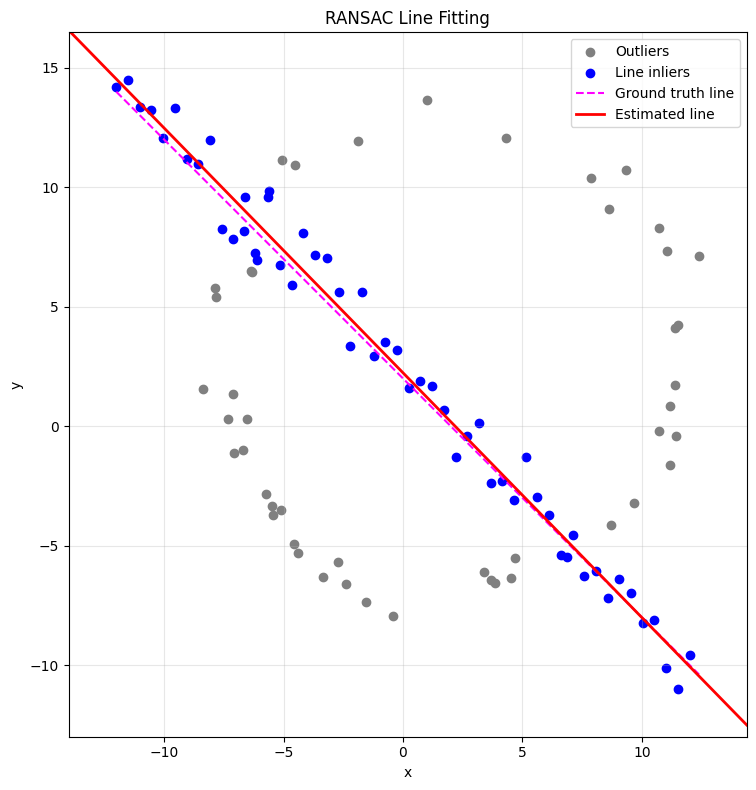

In [6]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(X[~inlier_mask, 0], X[~inlier_mask, 1],color="gray", label="Outliers")

ax.scatter(X[inlier_mask, 0], X[inlier_mask, 1],color="blue", label="Line inliers")

ax.plot(x_plot, m * x_plot + b_gt,color="magenta", linestyle="--",label="Ground truth line")

ax.set_xlim(X[:, 0].min() - 2, X[:, 0].max() + 2)
ax.set_ylim(X[:, 1].min() - 2, X[:, 1].max() + 2)

point_on_line = d * normal
direction = np.array([-b, a])

ax.axline(point_on_line,point_on_line + direction,color="red", linewidth=2,label="Estimated line")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("RANSAC Line Fitting")
ax.set_aspect("equal", adjustable="box")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Question 02 b**

In [11]:
X_remaining = X[~inlier_mask]

circle_threshold = 2.5 * 0.625
circle_min_inliers = max(3, int(np.ceil(0.70 * len(X_remaining))))
circle_iterations = 1000

rng_circle = np.random.default_rng(43)

best_circle_mask = None
best_circle_center = None
best_circle_radius = None
best_circle_count = 0
best_circle_error = np.inf

for _ in range(circle_iterations):
    indices = rng_circle.choice(len(X_remaining), 3, replace=False)
    points = X_remaining[indices]

    p0 = points[0]
    differences = points[1:] - p0

    A = 2.0 * differences
    rhs = np.sum(differences ** 2, axis=1)

    if np.linalg.cond(A) > 1e6:
        continue

    offset = np.linalg.solve(A, rhs)
    center = p0 + offset
    radius = np.linalg.norm(offset)

    if not np.isfinite(radius) or radius <= 0:
        continue

    radial_errors = np.abs(
        np.linalg.norm(X_remaining - center, axis=1) - radius
    )

    mask = radial_errors <= circle_threshold
    count = np.count_nonzero(mask)

    if count < circle_min_inliers:
        continue

    error = np.mean(radial_errors[mask] ** 2)

    if count > best_circle_count or (
        count == best_circle_count and error < best_circle_error
    ):
        best_circle_count = count
        best_circle_error = error
        best_circle_mask = mask.copy()
        best_circle_center = center.copy()
        best_circle_radius = radius

        best_circle_sample = points.copy()

In [12]:
def circle_objective(parameters, points):
    xc, yc, radius = parameters
    radial_residuals = (
        np.linalg.norm(points - np.array([xc, yc]), axis=1) - radius
    )
    return np.sum(radial_residuals ** 2)


circle_result = minimize(
    circle_objective,
    x0=np.array([
        best_circle_center[0],
        best_circle_center[1],
        best_circle_radius
    ]),
    args=(X_remaining[best_circle_mask],),
    bounds=[(None, None), (None, None), (1e-8, None)],
    method="Powell"
)

xc, yc, circle_radius = circle_result.x
circle_center = np.array([xc, yc])

radial_errors = np.abs(
    np.linalg.norm(X_remaining - circle_center, axis=1) - circle_radius
)

circle_inlier_mask = radial_errors <= circle_threshold

print(f"Remaining points = {len(X_remaining)}")
print(f"Center = ({xc:.6f}, {yc:.6f})")
print(f"Radius = {circle_radius:.6f}")
print(f"Radial error threshold = {circle_threshold:.4f}")
print(f"Minimum consensus = {circle_min_inliers}")
print(f"Final consensus = {circle_inlier_mask.sum()}")
print(f"Iterations = {circle_iterations}")
print(
    f"Inlier radial RMSE = "
    f"{np.sqrt(np.mean(radial_errors[circle_inlier_mask] ** 2)):.6f}"
)

Remaining points = 46
Center = (1.949830, 2.987536)
Radius = 9.891839
Radial error threshold = 1.5625
Minimum consensus = 33
Final consensus = 46
Iterations = 1000
Inlier radial RMSE = 0.592452


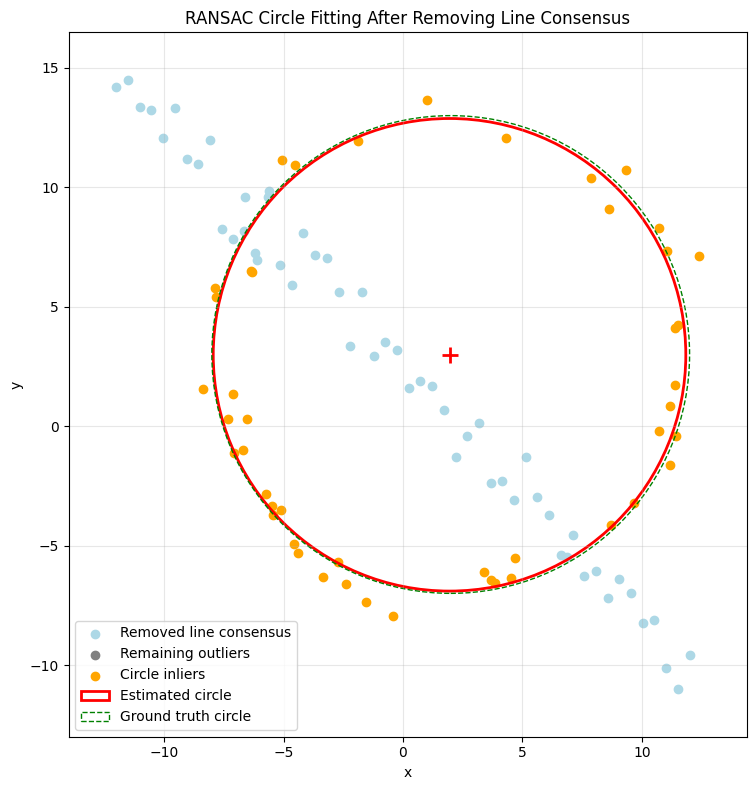

In [13]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(X[inlier_mask, 0], X[inlier_mask, 1], color="lightblue", label="Removed line consensus")

ax.scatter(X_remaining[~circle_inlier_mask, 0], X_remaining[~circle_inlier_mask, 1],color="gray", label="Remaining outliers")

ax.scatter(X_remaining[circle_inlier_mask, 0],X_remaining[circle_inlier_mask, 1],color="orange", label="Circle inliers")

ax.add_patch(plt.Circle(circle_center, circle_radius,color="red", fill=False, linewidth=2, label="Estimated circle"))

ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color="green", fill=False, linestyle="--", label="Ground truth circle"))

ax.plot(xc, yc, "r+", markersize=12, markeredgewidth=2)

ax.set_xlim(X[:, 0].min() - 2, X[:, 0].max() + 2)
ax.set_ylim(X[:, 1].min() - 2, X[:, 1].max() + 2)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("RANSAC Circle Fitting After Removing Line Consensus")
ax.set_aspect("equal", adjustable="box")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Question 2 c**

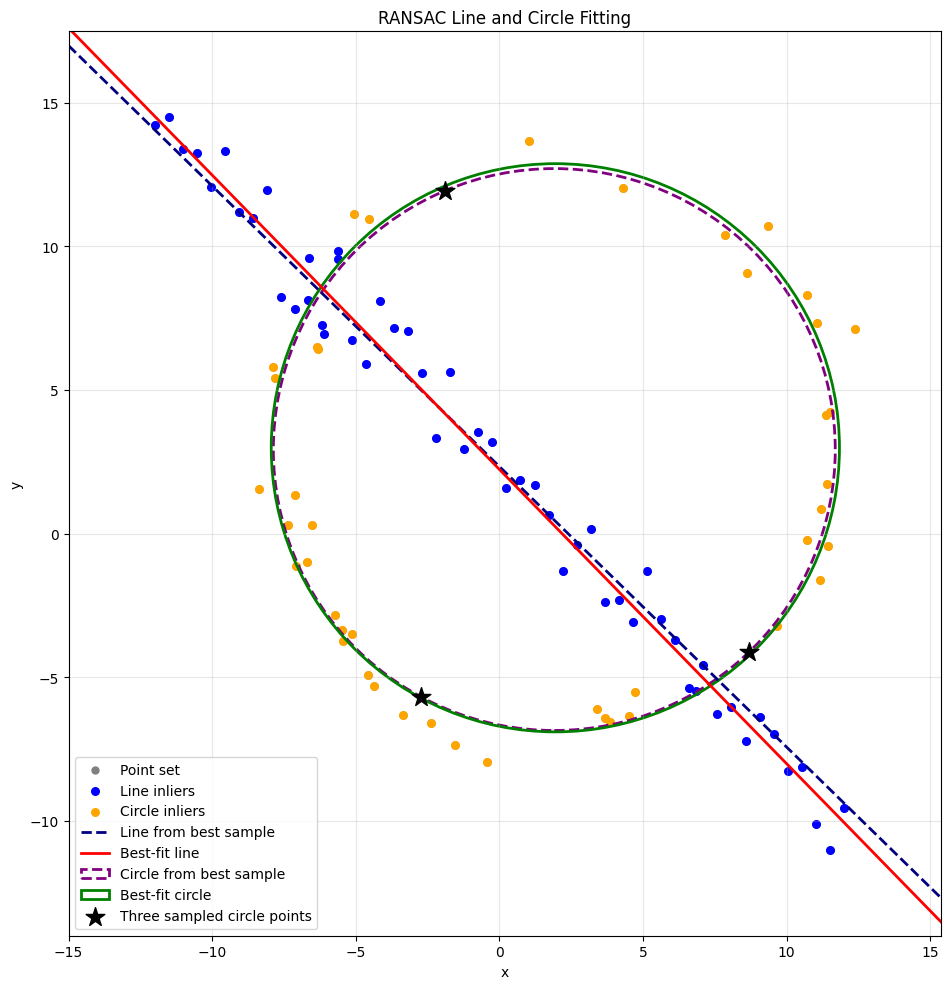

In [14]:
fig, ax = plt.subplots(figsize=(10, 10))

ax.scatter(X[:, 0], X[:, 1],color="gray", s=25, label="Point set")

ax.scatter(X[inlier_mask, 0], X[inlier_mask, 1],color="blue", s=30, label="Line inliers")

ax.scatter(X_remaining[circle_inlier_mask, 0], X_remaining[circle_inlier_mask, 1], color="orange", s=30, label="Circle inliers")

ax.set_xlim(X[:, 0].min() - 3, X[:, 0].max() + 3)
ax.set_ylim(X[:, 1].min() - 3, X[:, 1].max() + 3)

sample_line_point = best_d * best_normal
sample_line_direction = np.array([-best_normal[1], best_normal[0]])

ax.axline(sample_line_point,sample_line_point + sample_line_direction,color="navy", linestyle="--", linewidth=2,label="Line from best sample")

fitted_line_point = d * np.array([a, b])
fitted_line_direction = np.array([-b, a])

ax.axline(fitted_line_point, fitted_line_point + fitted_line_direction, color="red", linewidth=2, label="Best-fit line")

ax.add_patch(plt.Circle(best_circle_center,best_circle_radius,color="purple",fill=False, linestyle="--",linewidth=2,label="Circle from best sample"))

ax.add_patch(plt.Circle(circle_center,circle_radiuscolor="green",fill=False,linewidth=2,label="Best-fit circle"))

ax.scatter(best_circle_sample[:, 0],best_circle_sample[:, 1],color="black",marker="*",s=200,zorder=10, label="Three sampled circle points")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("RANSAC Line and Circle Fitting")
ax.set_aspect("equal", adjustable="box")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# **Question 3**

In [7]:
%matplotlib inline

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import base64
from pathlib import Path
from IPython.display import display, FileLink

In [8]:
def create_point_selector(image_path, output_path):
    image = cv.imread(image_path)

    if image is None:
        raise FileNotFoundError(image_path)

    success, encoded = cv.imencode(".jpg", image)

    if not success:
        raise RuntimeError("Image encoding failed.")

    image_data = base64.b64encode(encoded.tobytes()).decode()

    page = """
<!DOCTYPE html>
<html>
<head>
<meta charset="utf-8">
<style>
body {font-family: sans-serif; margin: 24px;}
canvas {max-width: 100%; height: auto; cursor: crosshair;}
textarea {width: 95%; height: 80px;}
</style>
</head>
<body>
<p>Click: top-left → top-right → bottom-right → bottom-left.</p>
<button id="reset">Reset</button>
<p><canvas id="canvas"></canvas></p>
<p>Copy these coordinates into the notebook:</p>
<textarea id="coordinates" readonly></textarea>
<script>
const image = new Image();
const canvas = document.getElementById("canvas");
const ctx = canvas.getContext("2d");
const output = document.getElementById("coordinates");
let points = [];

function draw() {
    ctx.drawImage(image, 0, 0);
    ctx.fillStyle = "red";
    ctx.font = Math.max(16, image.width / 60) + "px sans-serif";
    points.forEach(([x, y], i) => {
        ctx.beginPath();
        ctx.arc(x, y, Math.max(4, image.width / 200), 0, 2 * Math.PI);
        ctx.fill();
        ctx.fillText(String(i + 1), x + 10, y - 10);
    });
    output.value = JSON.stringify(points);
}

image.onload = () => {
    canvas.width = image.width;
    canvas.height = image.height;
    draw();
};

canvas.onclick = event => {
    if (points.length === 4) return;
    const rect = canvas.getBoundingClientRect();
    const x = (event.clientX - rect.left) * canvas.width / rect.width;
    const y = (event.clientY - rect.top) * canvas.height / rect.height;
    points.push([Math.round(x), Math.round(y)]);
    draw();
};

document.getElementById("reset").onclick = () => {
    points = [];
    draw();
};

image.src = "data:image/jpeg;base64,IMAGE_DATA";
</script>
</body>
</html>
"""

    Path(output_path).write_text(
        page.replace("IMAGE_DATA", image_data),
        encoding="utf-8"
    )

    display(FileLink(output_path))

In [22]:
building_1 = "/kaggle/input/datasets/isithadinujaya/sl-images/Town-Hall-Colombo.jpg"
flag_1 = "/kaggle/input/datasets/isithadinujaya/sl-images/sri lanka flag.png"


create_point_selector(building_1, "select_points_1.html")

building_2 = "/kaggle/input/datasets/isithadinujaya/frame-picture/feame.jpeg"
flag_2 = "/kaggle/input/datasets/isithadinujaya/frame-picture/IMG_8393.JPG"


create_point_selector(building_2, "select_points_2.html")


/kaggle/working/select_points_1.html

/kaggle/working/select_points_2.html

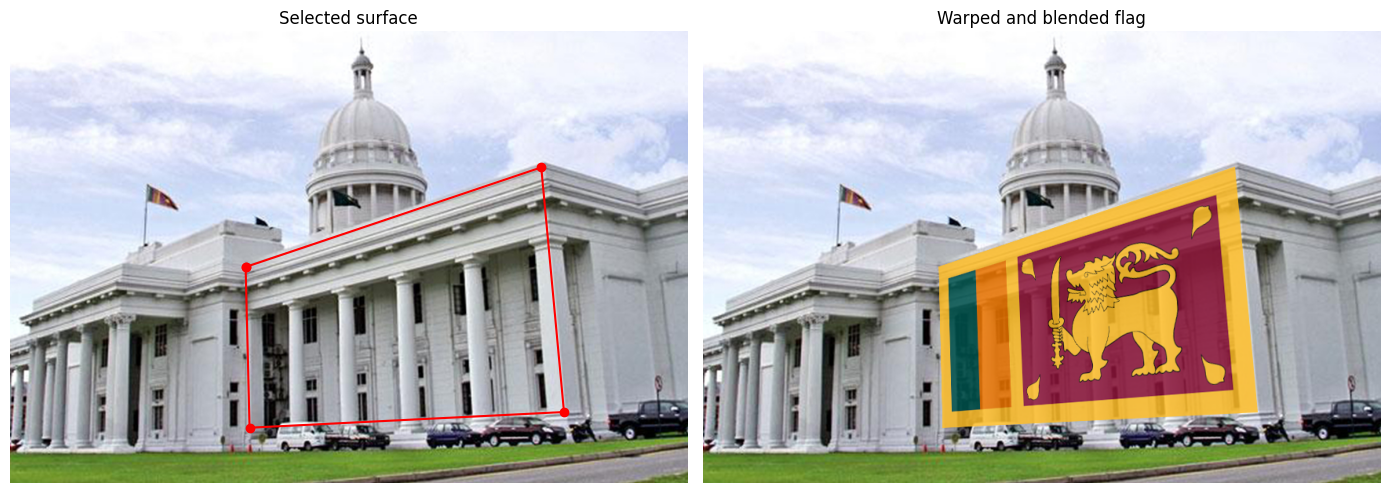

Homography:
[[ 2.27115242e-01 -1.79063309e-02  3.00000000e+02]
 [-2.95906521e-01  5.94863913e-01  3.00000000e+02]
 [-5.47044462e-04 -1.10751957e-04  1.00000000e+00]]


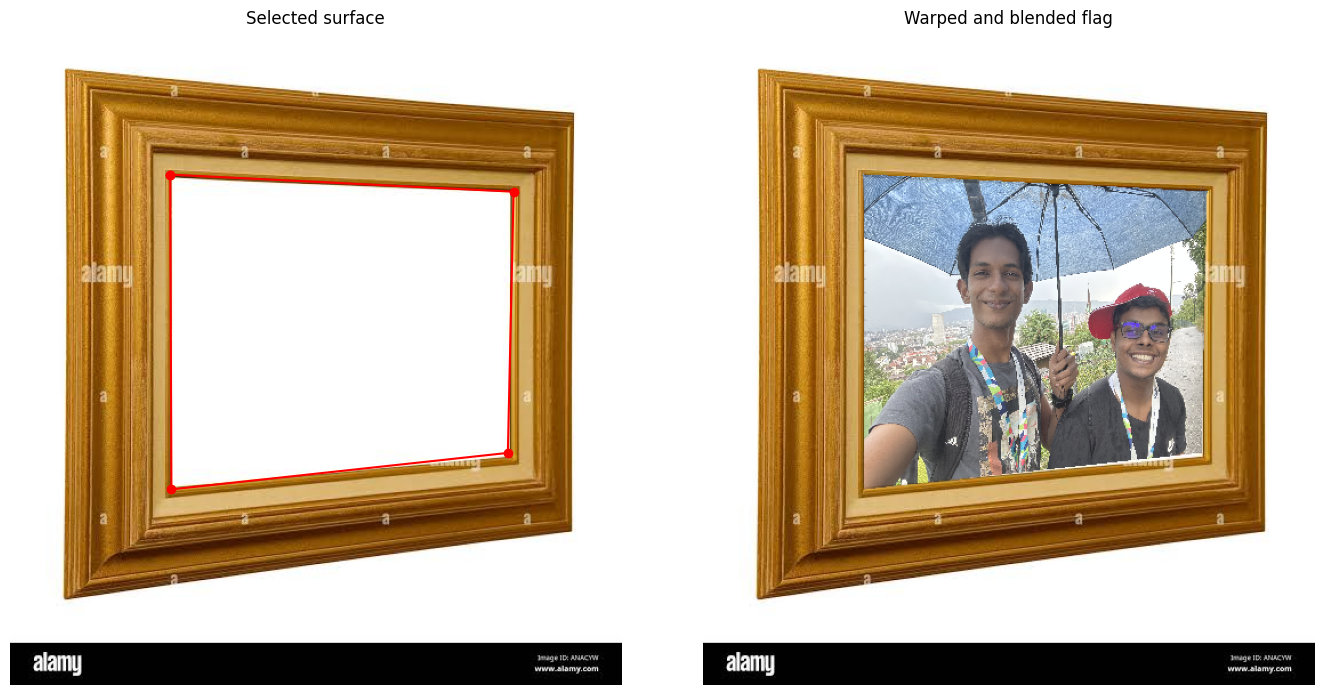

Homography:
[[9.74899901e-02 1.44434622e-03 1.40000000e+02]
 [1.09651904e-02 9.44669348e-02 1.25000000e+02]
 [5.17430672e-05 7.89751063e-06 1.00000000e+00]]


In [23]:
def warp_and_blend(building_path, flag_path, points, output_path):
    building = cv.imread(building_path)
    flag = cv.imread(flag_path)

    if building is None or flag is None:
        raise FileNotFoundError("Check the image paths.")

    destination = np.asarray(points, dtype=np.float32)

    if destination.shape != (4, 2):
        raise ValueError("Paste exactly four [x, y] coordinates.")

    if not cv.isContourConvex(destination.reshape(-1, 1, 2)):
        raise ValueError("Select four corners in the specified order.")

    h, w = flag.shape[:2]
    height, width = building.shape[:2]

    source = np.float32([[0, 0],[w - 1, 0],[w - 1, h - 1],[0, h - 1]])

    H = cv.getPerspectiveTransform(source, destination)

    warped = cv.warpPerspective(flag.astype(np.float32), H, (width, height))

    mask = cv.warpPerspective(np.ones((h, w), dtype=np.float32),H, (width, height))

    opacity = 0.85
    alpha = opacity * np.clip(mask, 0, 1)[..., None]

    result = (building.astype(np.float32) * (1 - alpha) + opacity * warped)

    result = np.clip(result, 0, 255).astype(np.uint8)
    cv.imwrite(output_path, result)

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))

    axes[0].imshow(cv.cvtColor(building, cv.COLOR_BGR2RGB))
    polygon = np.vstack((destination, destination[0]))
    axes[0].plot(polygon[:, 0], polygon[:, 1], "ro-")
    axes[0].set_title("Selected surface")

    axes[1].imshow(cv.cvtColor(result, cv.COLOR_BGR2RGB))
    axes[1].set_title("Warped and blended flag")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print("Homography:")
    print(H)

    return result, H


points_1 = [[300,300],[677,173],[706,485],[305,505]]
points_2 = [[140,125],[441,140],[436,369],[141,401]]

result_1, H_1 = warp_and_blend(
    building_1, flag_1, points_1, "result_1.png"
)

result_2, H_2 = warp_and_blend(
    building_2, flag_2, points_2, "result_2.png"
)

# **Question 4**

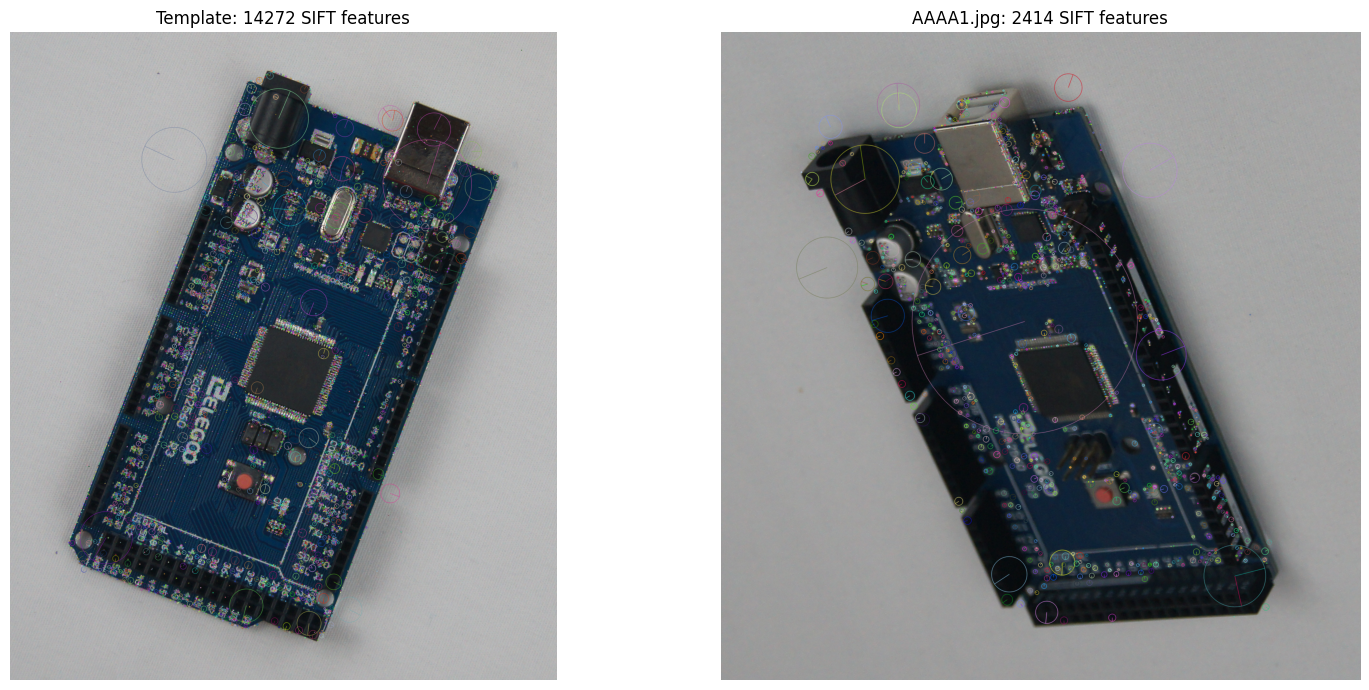

In [25]:
%matplotlib inline

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

image_dir = Path("/kaggle/input/datasets/isithadinujaya/images-a-2/a2images/a2images/pcbs")
template_path = image_dir / "AECC1.jpg"

template = cv.imread(str(template_path))

template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)

pcb_paths = sorted(
    path for path in image_dir.iterdir()
    if path.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
    and path != template_path
)


sift = cv.SIFT_create()
kp_template, des_template = sift.detectAndCompute(template_gray, None)

pcb = cv.imread(str(pcb_paths[0]))

pcb_gray = cv.cvtColor(pcb, cv.COLOR_BGR2GRAY)
kp_pcb, des_pcb = sift.detectAndCompute(pcb_gray, None)

template_features = cv.drawKeypoints(
    template, kp_template, None,
    flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

pcb_features = cv.drawKeypoints(
    pcb, kp_pcb, None,
    flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(cv.cvtColor(template_features, cv.COLOR_BGR2RGB))
axes[0].set_title(f"Template: {len(kp_template)} SIFT features")

axes[1].imshow(cv.cvtColor(pcb_features, cv.COLOR_BGR2RGB))
axes[1].set_title(f"{pcb_paths[0].name}: {len(kp_pcb)} SIFT features")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

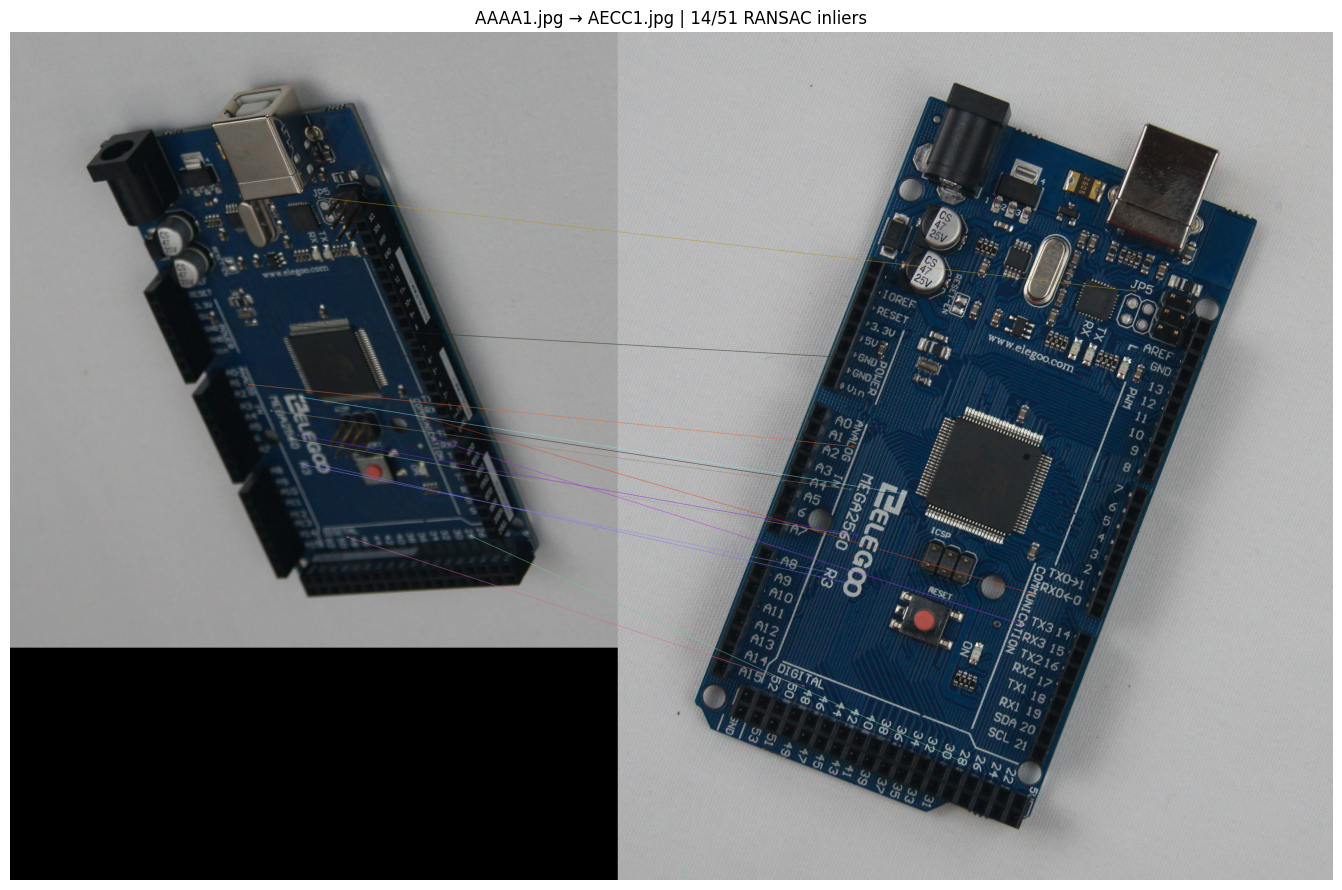

Homography:
[[ 1.19724748e+00 -1.10813714e+00  1.04572635e+03]
 [ 6.36521013e-01  9.48494605e-01 -3.12486736e+02]
 [ 2.84558350e-05 -7.27532973e-05  1.00000000e+00]]


In [26]:
def estimate_homography(keypoints, descriptors):

    matcher = cv.BFMatcher(cv.NORM_L2, crossCheck=False)
    candidate_matches = matcher.knnMatch(descriptors, des_template, k=2)

    good_matches = []

    for pair in candidate_matches:
        if len(pair) == 2:
            first, second = pair
            if first.distance < 0.75 * second.distance:
                good_matches.append(first)

    source_points = np.float32([keypoints[match.queryIdx].pt for match in good_matches]).reshape(-1, 1, 2)

    destination_points = np.float32([kp_template[match.trainIdx].pt for match in good_matches]).reshape(-1, 1, 2)

    H, inliers = cv.findHomography(source_points,destination_points,cv.RANSAC,ransacReprojThreshold=3.0,maxIters=5000,confidence=0.995)
    return H, good_matches, inliers


def draw_inlier_matches(image, keypoints, matches, inliers):
    return cv.drawMatches(image,keypoints,template,kp_template,matches,None,matchesMask=inliers.ravel().tolist(),flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)


H, good_matches, match_inliers = estimate_homography(kp_pcb, des_pcb)

matches_image = draw_inlier_matches(
    pcb, kp_pcb, good_matches, match_inliers
)

plt.figure(figsize=(18, 9))
plt.imshow(cv.cvtColor(matches_image, cv.COLOR_BGR2RGB))
plt.title(
    f"{pcb_paths[0].name} → AECC1.jpg | "
    f"{int(match_inliers.sum())}/{len(good_matches)} RANSAC inliers"
)
plt.axis("off")
plt.tight_layout()
plt.show()

print("Homography:")
print(H)

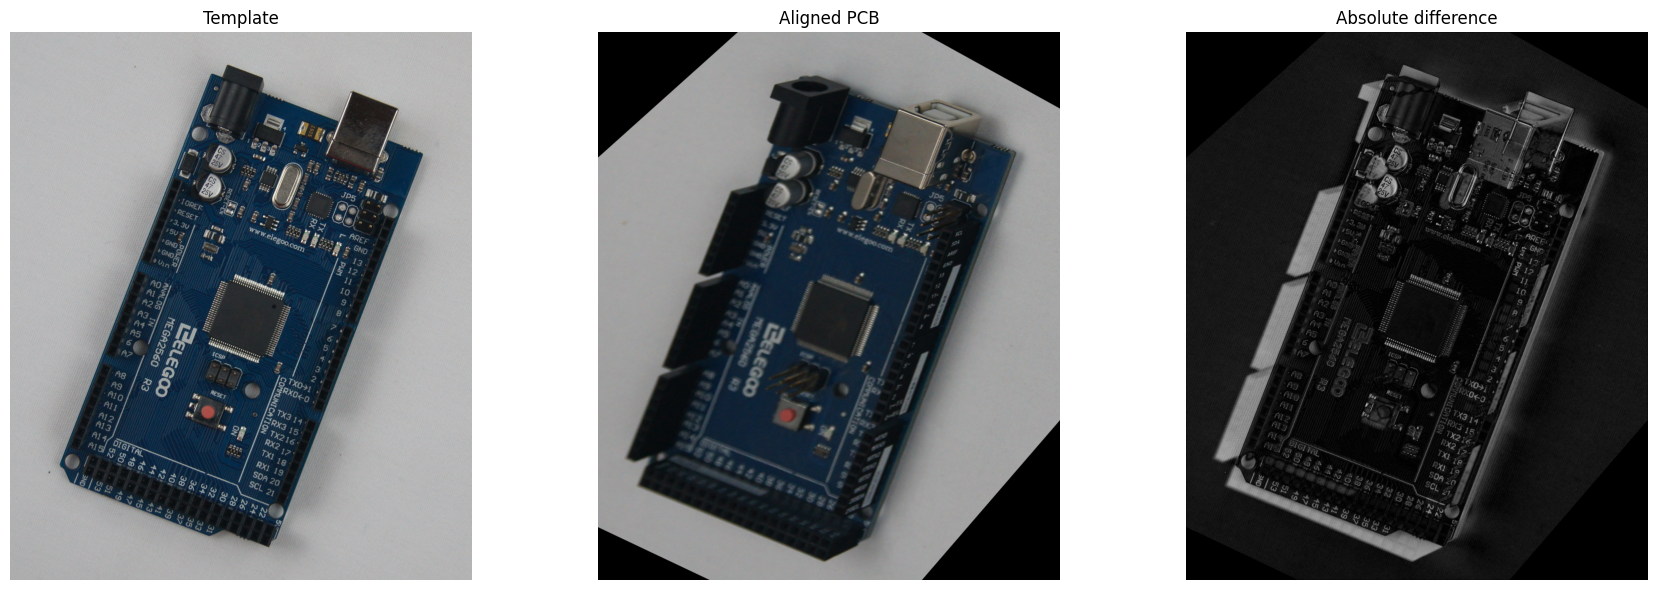

In [27]:
def warp_and_difference(image, homography):
    height, width = template.shape[:2]

    aligned = cv.warpPerspective(image, homography,(width, height),flags=cv.INTER_LINEAR)

    source_mask = np.full(image.shape[:2], 255, dtype=np.uint8)

    valid_mask = cv.warpPerspective(source_mask,homography,(width, height),flags=cv.INTER_NEAREST)

    valid_mask = cv.erode(valid_mask,np.ones((3, 3), dtype=np.uint8),borderType=cv.BORDER_CONSTANT,borderValue=0)

    aligned_gray = cv.cvtColor(aligned, cv.COLOR_BGR2GRAY)

    difference = cv.absdiff(template_gray, aligned_gray)
    difference[valid_mask == 0] = 0

    return aligned, difference, valid_mask


aligned, difference, valid_mask = warp_and_difference(pcb, H)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(cv.cvtColor(template, cv.COLOR_BGR2RGB))
axes[0].set_title("Template")

axes[1].imshow(cv.cvtColor(aligned, cv.COLOR_BGR2RGB))
axes[1].set_title("Aligned PCB")

axes[2].imshow(difference, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Absolute difference")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

AAAA1.jpg: inliers=14, mean absolute difference=28.407, valid coverage=88.8%
ADAD1.jpg: inliers=190, mean absolute difference=31.151, valid coverage=98.0%
AECC2.jpg: inliers=3833, mean absolute difference=3.015, valid coverage=98.3%
AECC3.jpg: inliers=4991, mean absolute difference=2.792, valid coverage=98.8%
AECC4.jpg: inliers=3392, mean absolute difference=3.590, valid coverage=98.4%


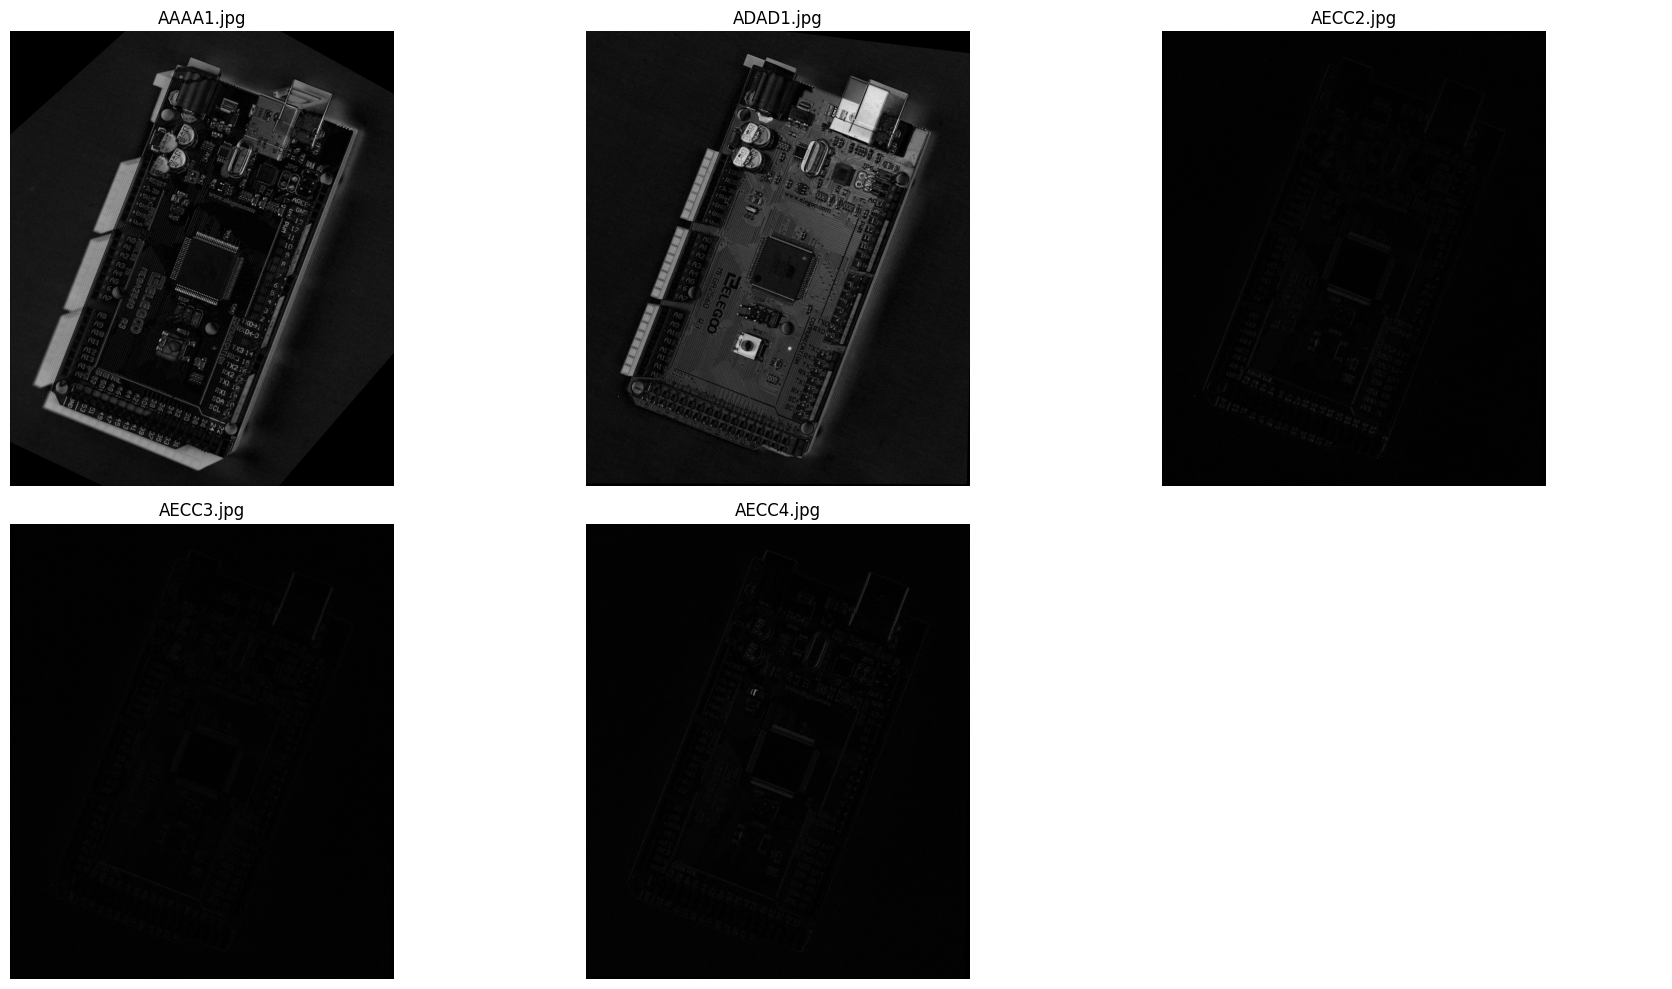

Results saved to: /kaggle/working/pcb_results


In [28]:
output_dir = Path("/kaggle/working/pcb_results")
output_dir.mkdir(parents=True, exist_ok=True)

results = []

for index, path in enumerate(pcb_paths):
    if index == 0:
        current_aligned = aligned
        current_difference = difference
        current_mask = valid_mask
        current_matches = matches_image
        current_H = H
        inlier_count = int(match_inliers.sum())
    else:
        image = cv.imread(str(path))

        gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
        keypoints, descriptors = sift.detectAndCompute(gray, None)

        current_H, matches, inliers = estimate_homography(keypoints, descriptors)

        current_matches = draw_inlier_matches(image, keypoints, matches, inliers)

        current_aligned, current_difference, current_mask = (warp_and_difference(image, current_H))

        inlier_count = int(inliers.sum())

    prefix = f"{path.stem}_{path.suffix.lstrip('.')}"

    cv.imwrite(str(output_dir / f"{prefix}_aligned.png"),current_aligned)

    cv.imwrite(str(output_dir / f"{prefix}_difference.png"),current_difference)

    cv.imwrite(str(output_dir / f"{prefix}_matches.png"),current_matches)

    cv.imwrite(str(output_dir / f"{prefix}_valid_mask.png"),current_mask)

    np.savetxt(output_dir / f"{prefix}_homography.txt",current_H)

    results.append((path.name, current_difference.copy()))

    valid_pixels = current_mask > 0
    mean_error = current_difference[valid_pixels].mean()
    coverage = 100 * valid_pixels.mean()

    print(
        f"{path.name}: inliers={inlier_count}, "
        f"mean absolute difference={mean_error:.3f}, "
        f"valid coverage={coverage:.1f}%"
    )

if results:
    columns = min(3, len(results))
    rows = int(np.ceil(len(results) / columns))

    fig, axes = plt.subplots(
        rows, columns,
        figsize=(6 * columns, 5 * rows),
        squeeze=False
    )

    for ax in axes.ravel():
        ax.axis("off")

    for ax, (name, diff) in zip(axes.ravel(), results):
        ax.imshow(diff, cmap="gray", vmin=0, vmax=255)
        ax.set_title(name)

    plt.tight_layout()
    plt.show()